# DOA-DQN: Dream Optimization Algorithm for Deep Q-Network Hyperparameter Tuning

A professional implementation of hyperparameter optimization for DQN using DOA.

**Combines deep reinforcement learning with metaheuristic optimization.**

---

**Author:** Research Project  
**Date:** December 2025  
**License:** MIT


## 1. Imports and Configuration


In [10]:
import numpy as np
import gym
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
from typing import Callable, Tuple, Optional, Dict, List
import warnings
from pathlib import Path
import json
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

# Set style for professional plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Configuration
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("✓ Imports successful")
print(f"✓ PyTorch version: {torch.__version__}")
print(f"✓ NumPy version: {np.__version__}")


✓ Imports successful
✓ PyTorch version: 2.7.0
✓ NumPy version: 1.26.4


## 2. Part 1: Deep Q-Network Implementation

### 2.1 Replay Buffer


In [11]:
class ReplayBuffer:
    """Experience replay buffer for DQN."""

    def __init__(self, capacity: int = 10000):
        self.capacity = capacity
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """Add experience to buffer."""
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        """Sample batch from buffer."""
        indices = np.random.choice(len(self.buffer), batch_size, replace=False)
        states, actions, rewards, next_states, dones = zip(*[self.buffer[i] for i in indices])

        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)

print("✓ ReplayBuffer class defined")


✓ ReplayBuffer class defined


### 2.2 Q-Network Architecture


In [12]:
class QNetwork(nn.Module):
    """Q-value approximation network."""

    def __init__(self, state_dim: int, action_dim: int, hidden_size: int = 64, n_layers: int = 2):
        super(QNetwork, self).__init__()

        layers = []
        prev_dim = state_dim

        for _ in range(n_layers):
            layers.append(nn.Linear(prev_dim, hidden_size))
            layers.append(nn.ReLU())
            prev_dim = hidden_size

        layers.append(nn.Linear(prev_dim, action_dim))

        self.net = nn.Sequential(*layers)

    def forward(self, state):
        return self.net(state)

print("✓ QNetwork class defined")


✓ QNetwork class defined


### 2.3 DQN Agent


In [13]:
class DQNAgent:
    """Deep Q-Network Agent with Adam optimizer."""

    def __init__(
        self,
        env: gym.Env,
        hyperparams: Dict,
        device: str = 'cpu',
        seed: int = 42
    ):
        """
        Initialize DQN Agent.

        Parameters
        ----------
        env : gym.Env
            Gym environment
        hyperparams : Dict
            Dictionary containing all hyperparameters:
            - learning_rate (float)
            - gamma (float): discount factor
            - epsilon_start (float)
            - epsilon_end (float)
            - epsilon_decay_steps (int)
            - batch_size (int)
            - replay_buffer_size (int)
            - target_update_freq (int)
            - hidden_size (int)
            - n_layers (int)
            - adam_beta1 (float)
            - adam_beta2 (float)
            - adam_epsilon (float)
        device : str
            'cpu' or 'cuda'
        seed : int
            Random seed
        """
        np.random.seed(seed)
        torch.manual_seed(seed)

        self.env = env
        self.device = device
        self.hyperparams = hyperparams

        # Extract state and action dimensions
        if isinstance(env.observation_space, gym.spaces.Box):
            self.state_dim = int(np.prod(env.observation_space.shape))
        else:
            self.state_dim = env.observation_space.n

        self.action_dim = env.action_space.n if isinstance(env.action_space, gym.spaces.Discrete) else 1

        # Networks
        self.q_network = QNetwork(
            self.state_dim,
            self.action_dim,
            hidden_size=int(hyperparams['hidden_size']),
            n_layers=int(hyperparams['n_layers'])
        ).to(device)

        self.target_network = QNetwork(
            self.state_dim,
            self.action_dim,
            hidden_size=int(hyperparams['hidden_size']),
            n_layers=int(hyperparams['n_layers'])
        ).to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())

        # Optimizer with Adam hyperparameters
        self.optimizer = optim.Adam(
            self.q_network.parameters(),
            lr=hyperparams['learning_rate'],
            betas=(hyperparams['adam_beta1'], hyperparams['adam_beta2']),
            eps=hyperparams['adam_epsilon']
        )

        # Replay buffer
        self.replay_buffer = ReplayBuffer(int(hyperparams['replay_buffer_size']))

        # Hyperparameters
        self.gamma = hyperparams['gamma']
        self.epsilon_start = hyperparams['epsilon_start']
        self.epsilon_end = hyperparams['epsilon_end']
        self.epsilon_decay_steps = hyperparams['epsilon_decay_steps']
        self.batch_size = int(hyperparams['batch_size'])
        self.target_update_freq = int(hyperparams['target_update_freq'])

        # Training state
        self.step_count = 0
        self.episode_count = 0
        self.episode_rewards = []
        self.training_losses = []

    def get_epsilon(self) -> float:
        """Get current epsilon for epsilon-greedy exploration."""
        progress = min(self.step_count / self.epsilon_decay_steps, 1.0)
        return self.epsilon_start + (self.epsilon_end - self.epsilon_start) * progress

    def select_action(self, state: np.ndarray, training: bool = True) -> int:
        """Select action using epsilon-greedy policy."""
        if training and np.random.rand() < self.get_epsilon():
            return self.env.action_space.sample()

        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device)
            q_values = self.q_network(state_tensor)
            return q_values.argmax(1).item()

    def update(self):
        """Update Q-network with batch from replay buffer."""
        if len(self.replay_buffer) < self.batch_size:
            return

        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)

        states = torch.FloatTensor(states).to(self.device)
        actions = torch.LongTensor(actions).to(self.device)
        rewards = torch.FloatTensor(rewards).to(self.device)
        next_states = torch.FloatTensor(next_states).to(self.device)
        dones = torch.FloatTensor(dones).to(self.device)

        # Compute Q(s,a)
        q_values = self.q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        # Compute target Q(s',a')
        with torch.no_grad():
            max_next_q = self.target_network(next_states).max(1)[0]
            target_q = rewards + (1 - dones) * self.gamma * max_next_q

        # TD loss
        loss = nn.MSELoss()(q_values, target_q)

        # Update
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.q_network.parameters(), 1.0)
        self.optimizer.step()

        self.training_losses.append(loss.item())

        # Update target network
        if self.step_count % self.target_update_freq == 0:
            self.target_network.load_state_dict(self.q_network.state_dict())

    def train(self, num_steps: int, log_interval: int = 1000):
        """
        Train agent for specified number of steps.

        Parameters
        ----------
        num_steps : int
            Total steps to train
        log_interval : int
            Logging interval
        """
        state, _ = self.env.reset()
        episode_reward = 0

        for step in range(num_steps):
            # Select and execute action
            action = self.select_action(state, training=True)
            next_state, reward, terminated, truncated, _ = self.env.step(action)
            done = terminated or truncated

            # Store experience
            self.replay_buffer.push(state, action, reward, next_state, done)

            # Update network
            self.update()

            episode_reward += reward
            self.step_count += 1

            if done:
                self.episode_rewards.append(episode_reward)
                self.episode_count += 1
                state, _ = self.env.reset()
                episode_reward = 0
            else:
                state = next_state

            if (step + 1) % log_interval == 0 and len(self.episode_rewards) > 0:
                avg_reward = np.mean(self.episode_rewards[-10:])
                print(f"Step {step + 1}/{num_steps} | Avg Reward (last 10): {avg_reward:.2f}")

    def evaluate(self, num_episodes: int = 10) -> float:
        """
        Evaluate agent (greedy policy).

        Parameters
        ----------
        num_episodes : int
            Number of evaluation episodes

        Returns
        -------
        mean_reward : float
            Average reward over episodes
        """
        rewards = []

        for _ in range(num_episodes):
            state, _ = self.env.reset()
            episode_reward = 0
            done = False

            while not done:
                action = self.select_action(state, training=False)
                state, reward, terminated, truncated, _ = self.env.step(action)
                done = terminated or truncated
                episode_reward += reward

            rewards.append(episode_reward)

        return np.mean(rewards)

print("✓ DQNAgent class defined")


✓ DQNAgent class defined


## 3. Part 2: DOA Optimizer


In [14]:
class DOA:
    """Dream Optimization Algorithm for hyperparameter search."""

    def __init__(
        self,
        dim: int,
        bounds: list,
        pop_size: int = 20,
        max_iter: int = 100,
        u: float = 0.9,
        seed: Optional[int] = None,
        verbose: bool = False
    ):
        self.dim = dim
        self.bounds = np.array(bounds, dtype=float)
        self.pop_size = pop_size
        self.max_iter = max_iter
        self.u = u
        self.verbose = verbose

        assert self.bounds.shape == (dim, 2)
        assert np.all(self.bounds[:, 0] < self.bounds[:, 1])

        self.rng = np.random.RandomState(seed)
        self.T_d = int(0.9 * max_iter)
        self.k_q = self._compute_k_q()
        self.k_r = self._compute_k_r()

        self.history_best = []
        self.history_mean = []
        self.n_evals = 0

    def _compute_k_q(self) -> np.ndarray:
        k_q = np.zeros(5, dtype=int)
        for q in range(5):
            q_id = q + 1
            k_min = int(np.ceil(self.dim / (8.0 * q_id)))
            k_max = max(2, int(np.ceil(self.dim / (3.0 * q_id))))
            k_q[q] = self.rng.randint(k_min, k_max + 1)
        return k_q

    def _compute_k_r(self) -> int:
        k_min = 2
        k_max = max(2, int(np.ceil(self.dim / 3.0)))
        return self.rng.randint(k_min, k_max + 1)

    def _initialize_population(self) -> np.ndarray:
        low = self.bounds[:, 0]
        high = self.bounds[:, 1]
        return low + self.rng.rand(self.pop_size, self.dim) * (high - low)

    def _clip_bounds(self, X: np.ndarray) -> np.ndarray:
        low = self.bounds[:, 0]
        high = self.bounds[:, 1]
        return np.clip(X, low, high)

    def _exploration_phase(self, X: np.ndarray, fitness: np.ndarray, t: int) -> np.ndarray:
        X_new = X.copy()
        pop_per_group = self.pop_size // 5

        for q in range(5):
            start_idx = q * pop_per_group
            end_idx = self.pop_size if q == 4 else (q + 1) * pop_per_group
            group_indices = np.arange(start_idx, end_idx)

            group_fitness = fitness[group_indices]
            best_group_idx = group_indices[np.argmin(group_fitness)]
            X_best_group = X[best_group_idx].copy()

            for i in group_indices:
                X_new[i] = X_best_group.copy()
                k = self.k_q[q]
                forgetting_dims = self.rng.choice(self.dim, size=min(k, self.dim), replace=False)

                for j in forgetting_dims:
                    if self.rng.rand() < self.u:
                        low, high = self.bounds[j]
                        perturb = low + self.rng.rand() * (high - low)
                        alpha = 0.5 * (np.cos(np.pi * (t + self.max_iter - self.T_d) / self.max_iter) + 1.0)
                        X_new[i, j] = X_best_group[j] + perturb * alpha
                    else:
                        m = self.rng.randint(0, self.pop_size)
                        X_new[i, j] = X_new[m, j] if m <= i else X[m, j]

        return X_new

    def _exploitation_phase(self, X: np.ndarray, X_best: np.ndarray, t: int) -> np.ndarray:
        X_new = np.tile(X_best, (self.pop_size, 1))
        k = self.k_r
        forgetting_dims = self.rng.choice(self.dim, size=min(k, self.dim), replace=False)

        for i in range(self.pop_size):
            for j in forgetting_dims:
                low, high = self.bounds[j]
                perturb = low + self.rng.rand() * (high - low)
                alpha = 0.5 * (np.cos(np.pi * t / self.max_iter) + 1.0)
                X_new[i, j] = X_best[j] + perturb * alpha

        return X_new

    def optimize(self, fitness_fn: Callable) -> Tuple[np.ndarray, float, Dict]:
        """Run DOA optimization."""
        X = self._initialize_population()
        fitness = np.array([fitness_fn(x) for x in X])
        self.n_evals = self.pop_size

        best_idx = np.argmin(fitness)
        X_best = X[best_idx].copy()
        f_best = fitness[best_idx]

        self.history_best.append(f_best)
        self.history_mean.append(np.mean(fitness))

        if self.verbose:
            print(f"[DOA] Iter 0 - Best: {f_best:.6e}, Mean: {np.mean(fitness):.6e}")

        for t in range(self.max_iter):
            X_new = self._exploration_phase(X, fitness, t) if t < self.T_d \
                    else self._exploitation_phase(X, X_best, t)

            X_new = self._clip_bounds(X_new)
            fitness_new = np.array([fitness_fn(x) for x in X_new])
            self.n_evals += self.pop_size

            improved = fitness_new < fitness
            X[improved] = X_new[improved]
            fitness[improved] = fitness_new[improved]

            best_idx = np.argmin(fitness)
            if fitness[best_idx] < f_best:
                f_best = fitness[best_idx]
                X_best = X[best_idx].copy()

            self.history_best.append(f_best)
            self.history_mean.append(np.mean(fitness))

            if self.verbose and (t + 1) % max(1, self.max_iter // 10) == 0:
                print(f"[DOA] Iter {t+1} - Best: {f_best:.6e}, Mean: {np.mean(fitness):.6e}")

        info = {
            'history_best': np.array(self.history_best),
            'history_mean': np.array(self.history_mean),
            'n_evals': self.n_evals,
        }

        return X_best, f_best, info

print("✓ DOA class defined")


✓ DOA class defined


## 4. Part 3: Hyperparameter Encoding/Decoding


In [15]:
class HyperparameterCodec:
    """Encode/decode hyperparameters from/to continuous vectors."""

    # Hyperparameter specifications (name, bounds, type, scale)
    SPECS = {
        'learning_rate': (1e-5, 1e-2, 'float', 'log'),
        'gamma': (0.90, 0.999, 'float', 'linear'),
        'epsilon_start': (0.5, 1.0, 'float', 'linear'),
        'epsilon_end': (0.01, 0.1, 'float', 'linear'),
        'epsilon_decay_steps': (10000, 100000, 'int', 'log'),
        'batch_size': (32, 256, 'int', 'discrete'),  # powers of 2
        'replay_buffer_size': (10000, 100000, 'int', 'log'),
        'target_update_freq': (100, 5000, 'int', 'log'),
        'hidden_size': (64, 512, 'int', 'discrete'),  # 64, 128, 256, 512
        'n_layers': (1, 4, 'int', 'discrete'),  # 1, 2, 3, 4
        'adam_beta1': (0.8, 0.99, 'float', 'linear'),
        'adam_beta2': (0.9, 0.9999, 'float', 'linear'),
        'adam_epsilon': (1e-8, 1e-4, 'float', 'log'),
    }

    HP_NAMES = list(SPECS.keys())
    DIM = len(HP_NAMES)

    @classmethod
    def get_bounds(cls) -> List[Tuple[float, float]]:
        """Get bounds for DOA [0, 1] normalized."""
        return [(0.0, 1.0) for _ in range(cls.DIM)]

    @classmethod
    def decode(cls, x: np.ndarray) -> Dict:
        """
        Decode normalized vector [0,1]^D to hyperparameters.

        Parameters
        ----------
        x : np.ndarray
            Normalized vector of shape (D,)

        Returns
        -------
        hyperparams : Dict
            Dictionary of hyperparameters
        """
        assert len(x) == cls.DIM, f"Expected {cls.DIM} dimensions, got {len(x)}"
        assert np.all((x >= 0) & (x <= 1)), "Input must be in [0, 1]"

        hyperparams = {}

        for i, hp_name in enumerate(cls.HP_NAMES):
            lower, upper, hp_type, scale = cls.SPECS[hp_name]
            x_norm = x[i]  # value in [0, 1]

            if scale == 'log':
                # Log scale
                hp_value = lower * (upper / lower) ** x_norm
            elif scale == 'linear':
                # Linear scale
                hp_value = lower + x_norm * (upper - lower)
            elif scale == 'discrete':
                # Discrete values (powers of 2 or fixed list)
                if hp_name == 'batch_size':
                    # [32, 64, 128, 256]
                    idx = int(x_norm * 3.99)  # 0, 1, 2, 3
                    hp_value = [32, 64, 128, 256][idx]
                elif hp_name == 'hidden_size':
                    # [64, 128, 256, 512]
                    idx = int(x_norm * 3.99)
                    hp_value = [64, 128, 256, 512][idx]
                elif hp_name == 'n_layers':
                    # [1, 2, 3, 4]
                    idx = int(x_norm * 3.99)
                    hp_value = [1, 2, 3, 4][idx]
                else:
                    idx = int(x_norm * (upper - lower + 0.99))
                    hp_value = lower + idx
            else:
                hp_value = lower + x_norm * (upper - lower)

            hyperparams[hp_name] = float(hp_value) if hp_type == 'float' else int(hp_value)

        return hyperparams

    @classmethod
    def validate(cls, hyperparams: Dict) -> bool:
        """Validate hyperparameters."""
        for name, value in hyperparams.items():
            if name not in cls.SPECS:
                return False
            lower, upper, _, _ = cls.SPECS[name]
            if value < lower or value > upper:
                return False
        return True

print("✓ HyperparameterCodec class defined")
print(f"  - Total hyperparameters: {HyperparameterCodec.DIM}")
print(f"  - Hyperparameters: {', '.join(HyperparameterCodec.HP_NAMES)}")


✓ HyperparameterCodec class defined
  - Total hyperparameters: 13
  - Hyperparameters: learning_rate, gamma, epsilon_start, epsilon_end, epsilon_decay_steps, batch_size, replay_buffer_size, target_update_freq, hidden_size, n_layers, adam_beta1, adam_beta2, adam_epsilon


## 5. Part 4: DOA-DQN Optimizer


In [16]:
class DOADQNOptimizer:
    """
    Main optimizer combining DOA with DQN hyperparameter tuning.
    """

    def __init__(
        self,
        env_name: str = 'CartPole-v1',
        doa_pop_size: int = 10,
        doa_iterations: int = 5,
        dqn_train_steps: int = 50000,
        dqn_eval_episodes: int = 10,
        device: str = 'cpu',
        output_dir: str = './results',
        verbose: bool = True
    ):
        """
        Initialize DOA-DQN optimizer.

        Parameters
        ----------
        env_name : str
            Gym environment name
        doa_pop_size : int
            DOA population size
        doa_iterations : int
            DOA iterations
        dqn_train_steps : int
            DQN training steps per evaluation
        dqn_eval_episodes : int
            Episodes for final DQN evaluation
        device : str
            'cpu' or 'cuda'
        output_dir : str
            Directory for saving results
        verbose : bool
            Verbosity flag
        """
        self.env_name = env_name
        self.doa_pop_size = doa_pop_size
        self.doa_iterations = doa_iterations
        self.dqn_train_steps = dqn_train_steps
        self.dqn_eval_episodes = dqn_eval_episodes
        self.device = device
        self.verbose = verbose

        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(parents=True, exist_ok=True)

        self.optimization_history = []

    def fitness_function(self, x: np.ndarray) -> float:
        """
        Evaluate DQN with given hyperparameters.

        Parameters
        ----------
        x : np.ndarray
            Normalized hyperparameter vector

        Returns
        -------
        fitness : float
            Negative mean reward (for minimization)
        """
        # Decode hyperparameters
        hyperparams = HyperparameterCodec.decode(x)

        if self.verbose:
            print(f"\n{'='*70}")
            print(f"Evaluating: {hyperparams}")

        try:
            # Create environment
            env = gym.make(self.env_name)

            # Create DQN agent
            agent = DQNAgent(env, hyperparams, device=self.device, seed=42)

            # Train
            if self.verbose:
                print(f"Training for {self.dqn_train_steps} steps...")
            agent.train(self.dqn_train_steps, log_interval=self.dqn_train_steps // 5)

            # Evaluate
            if self.verbose:
                print(f"Evaluating on {self.dqn_eval_episodes} episodes...")
            mean_reward = agent.evaluate(self.dqn_eval_episodes)

            # Fitness (negative for minimization)
            fitness = -mean_reward

            if self.verbose:
                print(f"Mean Reward: {mean_reward:.2f}, Fitness: {fitness:.6e}")

            # Store result
            self.optimization_history.append({
                'hyperparams': hyperparams,
                'mean_reward': float(mean_reward),
                'fitness': float(fitness),
                'episode_rewards': agent.episode_rewards[-10:] if len(agent.episode_rewards) >= 10 else agent.episode_rewards,
                'training_losses': agent.training_losses[-100:] if len(agent.training_losses) >= 100 else agent.training_losses,
            })

            env.close()
            return fitness

        except Exception as e:
            print(f"[ERROR] Evaluation failed: {e}")
            return float('inf')  # Return worst fitness on error

    def optimize(self) -> Tuple[Dict, float, Dict]:
        """
        Run DOA-DQN optimization.

        Returns
        -------
        best_hyperparams : Dict
            Best hyperparameters found
        best_reward : float
            Best mean reward achieved
        doa_info : Dict
            DOA optimization information (history, n_evals, etc.)
        """
        print("\n" + "="*70)
        print("Starting DOA-DQN Hyperparameter Optimization")
        print("="*70)
        print(f"Environment: {self.env_name}")
        print(f"DOA Population: {self.doa_pop_size}")
        print(f"DOA Iterations: {self.doa_iterations}")
        print(f"DQN Training Steps: {self.dqn_train_steps}")
        print("="*70 + "\n")

        # Initialize DOA
        doa = DOA(
            dim=HyperparameterCodec.DIM,
            bounds=HyperparameterCodec.get_bounds(),
            pop_size=self.doa_pop_size,
            max_iter=self.doa_iterations,
            seed=42,
            verbose=self.verbose
        )

        # Run optimization
        best_x, best_fitness, doa_info = doa.optimize(self.fitness_function)

        # Decode best solution
        best_hyperparams = HyperparameterCodec.decode(best_x)
        best_reward = -best_fitness

        # Save results
        self._save_results(best_hyperparams, best_reward, doa_info)

        print("\n" + "="*70)
        print("Optimization Complete!")
        print(f"Best Hyperparameters:\n{json.dumps(best_hyperparams, indent=2)}")
        print(f"Best Reward: {best_reward:.2f}")
        print(f"Total Evaluations: {doa_info['n_evals']}")
        print("="*70 + "\n")

        return best_hyperparams, best_reward, doa_info

    def _save_results(self, best_hyperparams: Dict, best_reward: float, doa_info: Dict):
        """Save optimization results to file."""
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        results_file = self.output_dir / f"doa_dqn_results_{timestamp}.json"

        results = {
            'timestamp': timestamp,
            'env': self.env_name,
            'best_hyperparams': best_hyperparams,
            'best_reward': float(best_reward),
            'optimization_history': self.optimization_history,
            'doa_info': {
                'n_evals': doa_info['n_evals'],
                'history_best': doa_info['history_best'].tolist(),
                'history_mean': doa_info['history_mean'].tolist(),
            }
        }

        with open(results_file, 'w') as f:
            json.dump(results, f, indent=2)

        print(f"\n[SAVED] Results to {results_file}")

print("✓ DOADQNOptimizer class defined")


✓ DOADQNOptimizer class defined


In [17]:
# Configuration
CONFIG = {
    'env_name': 'CartPole-v1',
    'doa_pop_size': 5,  # Small for demo - increase for better results
    'doa_iterations': 2,  # Small for demo - increase for better results
    'dqn_train_steps': 10000,  # Reduced for demo - increase for better results
    'dqn_eval_episodes': 5,
    'device': 'cpu',
    'output_dir': './doa_dqn_results',
    'verbose': True
}

print("Configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")


Configuration:
  env_name: CartPole-v1
  doa_pop_size: 5
  doa_iterations: 2
  dqn_train_steps: 10000
  dqn_eval_episodes: 5
  device: cpu
  output_dir: ./doa_dqn_results
  verbose: True


### 6.2 Run Optimization


In [18]:
# Initialize optimizer
optimizer = DOADQNOptimizer(**CONFIG)

# Run optimization
best_hp, best_reward, doa_info = optimizer.optimize()

print(f"\n[SUCCESS] Found best hyperparameters with reward: {best_reward:.2f}")



Starting DOA-DQN Hyperparameter Optimization
Environment: CartPole-v1
DOA Population: 5
DOA Iterations: 2
DQN Training Steps: 10000


Evaluating: {'learning_rate': 0.0006173770394704572, 'gamma': 0.9441374425325055, 'epsilon_start': 0.5499874579090014, 'epsilon_end': 0.05133240027692805, 'epsilon_decay_steps': 21562, 'batch_size': 32, 'replay_buffer_size': 44759, 'target_update_freq': 124, 'hidden_size': 256, 'n_layers': 4, 'adam_beta1': 0.8001479655097927, 'adam_beta2': 0.9991219347731927, 'adam_epsilon': 2.9507066707905306e-06}
Training for 10000 steps...
Step 2000/10000 | Avg Reward (last 10): 59.90
Step 4000/10000 | Avg Reward (last 10): 59.80
Step 6000/10000 | Avg Reward (last 10): 70.20
Step 8000/10000 | Avg Reward (last 10): 88.50
Step 10000/10000 | Avg Reward (last 10): 66.50
Evaluating on 5 episodes...
Mean Reward: 98.00, Fitness: -9.800000e+01

Evaluating: {'learning_rate': 0.0006838478430964043, 'gamma': 0.900699564216752, 'epsilon_start': 0.5115312125207079, 'epsilon_end':

## 7. Visualization and Analysis

### 7.1 DOA Convergence Plot


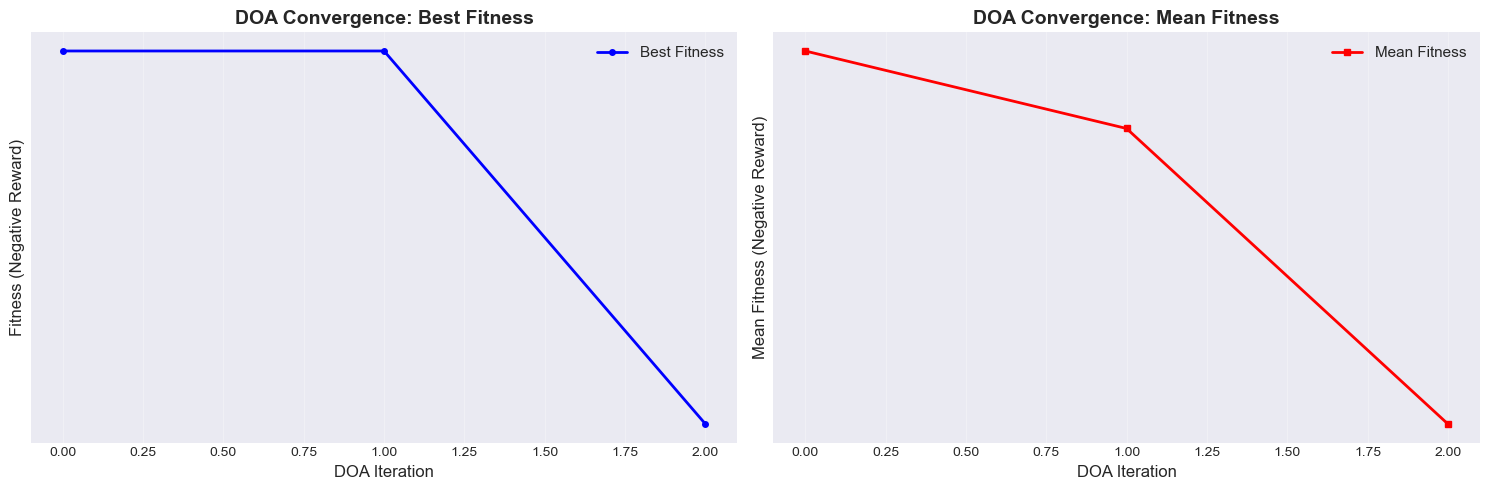

✓ DOA converged from -370.20 to -437.40


In [19]:
# Plot DOA convergence
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Best fitness over iterations
axes[0].plot(doa_info['history_best'], 'b-', linewidth=2, label='Best Fitness', marker='o', markersize=4)
axes[0].set_xlabel('DOA Iteration', fontsize=12)
axes[0].set_ylabel('Fitness (Negative Reward)', fontsize=12)
axes[0].set_title('DOA Convergence: Best Fitness', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)
axes[0].set_yscale('symlog')

# Mean fitness over iterations
axes[1].plot(doa_info['history_mean'], 'r-', linewidth=2, label='Mean Fitness', marker='s', markersize=4)
axes[1].set_xlabel('DOA Iteration', fontsize=12)
axes[1].set_ylabel('Mean Fitness (Negative Reward)', fontsize=12)
axes[1].set_title('DOA Convergence: Mean Fitness', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)
axes[1].set_yscale('symlog')

plt.tight_layout()
plt.show()

print(f"✓ DOA converged from {doa_info['history_best'][0]:.2f} to {doa_info['history_best'][-1]:.2f}")


### 7.2 Hyperparameter Analysis


Best Hyperparameters Found:
  learning_rate            : 3.312027701465945e-05
  gamma                    : 0.9387150001497508
  epsilon_start            : 0.5911180438940311
  epsilon_end              : 0.07798252692858873
  epsilon_decay_steps      : 26616
  batch_size               : 128
  replay_buffer_size       : 36957
  target_update_freq       : 113
  hidden_size              : 512
  n_layers                 : 3
  adam_beta1               : 0.8750785448403448
  adam_beta2               : 0.9925732206928001
  adam_epsilon             : 8.111253665497057e-06


IndexError: index 12 is out of bounds for axis 0 with size 12

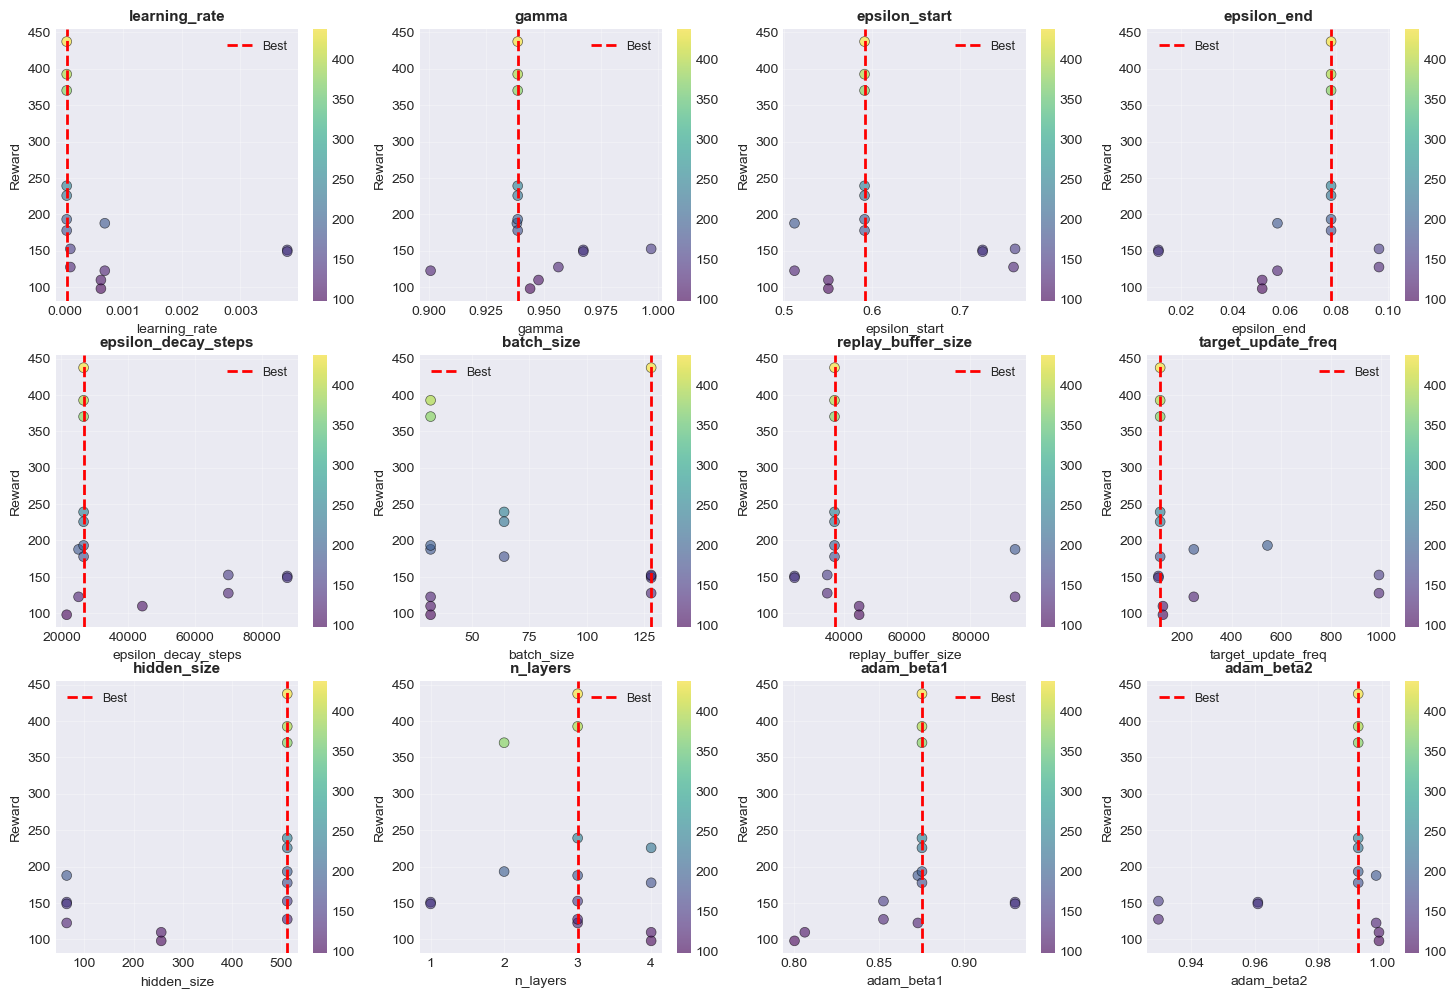

In [20]:
# Extract all hyperparameter values and rewards
hp_data = []
rewards = []

for entry in optimizer.optimization_history:
    hp_data.append(entry['hyperparams'])
    rewards.append(entry['mean_reward'])

# Create DataFrame for easier analysis
df = pd.DataFrame(hp_data)
df['reward'] = rewards

# Display best hyperparameters
print("="*70)
print("Best Hyperparameters Found:")
print("="*70)
for key, value in best_hp.items():
    print(f"  {key:25s}: {value}")
print("="*70)

# Plot hyperparameter distributions
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

hp_names = HyperparameterCodec.HP_NAMES
for i, hp_name in enumerate(hp_names):
    ax = axes[i]
    values = df[hp_name].values
    
    # Scatter plot: hyperparameter value vs reward
    scatter = ax.scatter(values, df['reward'], alpha=0.6, c=df['reward'], 
                        cmap='viridis', s=50, edgecolors='black', linewidth=0.5)
    ax.axvline(best_hp[hp_name], color='red', linestyle='--', linewidth=2, label='Best')
    ax.set_xlabel(hp_name, fontsize=10)
    ax.set_ylabel('Reward', fontsize=10)
    ax.set_title(f'{hp_name}', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    plt.colorbar(scatter, ax=ax)

plt.tight_layout()
plt.show()


### 7.3 Reward Evolution


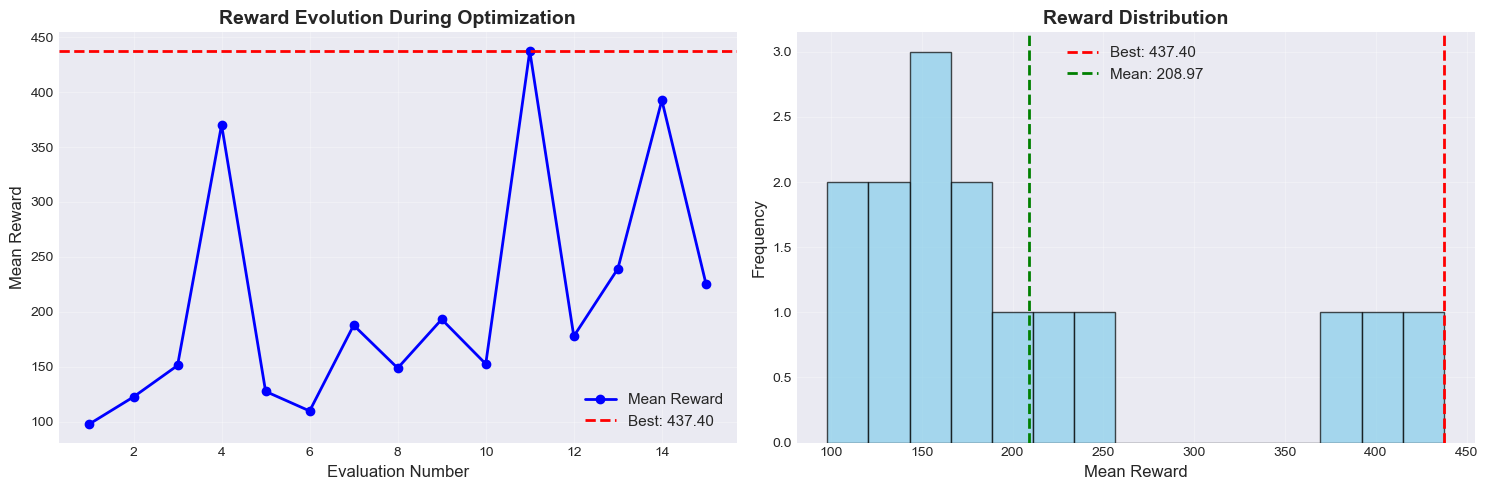

✓ Reward Statistics:
  Best: 437.40
  Mean: 208.97
  Std:  103.64
  Min:  98.00
  Max:  437.40


In [21]:
# Plot reward evolution over optimization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Reward over evaluations
eval_indices = range(1, len(rewards) + 1)
axes[0].plot(eval_indices, rewards, 'b-', linewidth=2, marker='o', markersize=6, label='Mean Reward')
axes[0].axhline(best_reward, color='red', linestyle='--', linewidth=2, label=f'Best: {best_reward:.2f}')
axes[0].set_xlabel('Evaluation Number', fontsize=12)
axes[0].set_ylabel('Mean Reward', fontsize=12)
axes[0].set_title('Reward Evolution During Optimization', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)

# Reward distribution
axes[1].hist(rewards, bins=min(20, len(rewards)), edgecolor='black', alpha=0.7, color='skyblue')
axes[1].axvline(best_reward, color='red', linestyle='--', linewidth=2, label=f'Best: {best_reward:.2f}')
axes[1].axvline(np.mean(rewards), color='green', linestyle='--', linewidth=2, label=f'Mean: {np.mean(rewards):.2f}')
axes[1].set_xlabel('Mean Reward', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Reward Distribution', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"✓ Reward Statistics:")
print(f"  Best: {best_reward:.2f}")
print(f"  Mean: {np.mean(rewards):.2f}")
print(f"  Std:  {np.std(rewards):.2f}")
print(f"  Min:  {np.min(rewards):.2f}")
print(f"  Max:  {np.max(rewards):.2f}")


### 7.4 Training Curves for Best Configuration


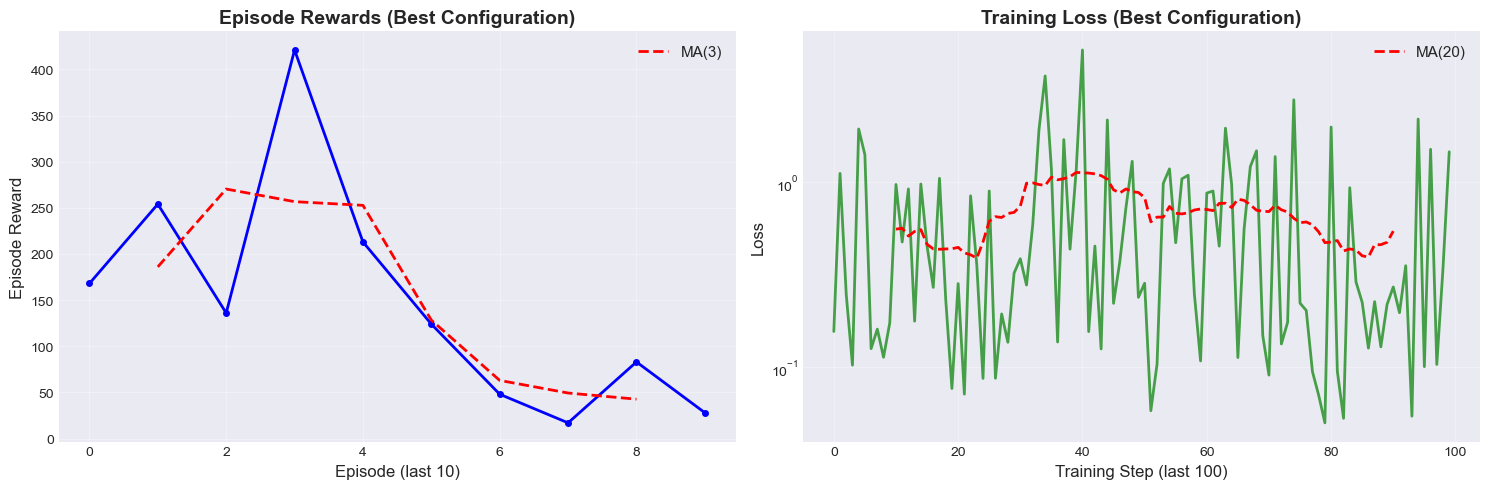

In [22]:
# Find the best configuration's training data
best_idx = np.argmax(rewards)
best_training_data = optimizer.optimization_history[best_idx]

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Episode rewards (if available)
if 'episode_rewards' in best_training_data and len(best_training_data['episode_rewards']) > 0:
    ep_rewards = best_training_data['episode_rewards']
    axes[0].plot(range(len(ep_rewards)), ep_rewards, 'b-', linewidth=2, marker='o', markersize=4)
    axes[0].set_xlabel('Episode (last 10)', fontsize=12)
    axes[0].set_ylabel('Episode Reward', fontsize=12)
    axes[0].set_title('Episode Rewards (Best Configuration)', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    if len(ep_rewards) > 1:
        # Moving average
        window = max(1, len(ep_rewards) // 3)
        ma = pd.Series(ep_rewards).rolling(window=window, center=True).mean()
        axes[0].plot(range(len(ma)), ma, 'r--', linewidth=2, label=f'MA({window})')
        axes[0].legend(fontsize=11)
else:
    axes[0].text(0.5, 0.5, 'No episode rewards available', 
                ha='center', va='center', transform=axes[0].transAxes, fontsize=12)
    axes[0].set_title('Episode Rewards (Best Configuration)', fontsize=14, fontweight='bold')

# Training losses (if available)
if 'training_losses' in best_training_data and len(best_training_data['training_losses']) > 0:
    losses = best_training_data['training_losses']
    axes[1].plot(range(len(losses)), losses, 'g-', linewidth=2, alpha=0.7)
    axes[1].set_xlabel('Training Step (last 100)', fontsize=12)
    axes[1].set_ylabel('Loss', fontsize=12)
    axes[1].set_title('Training Loss (Best Configuration)', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_yscale('log')
    if len(losses) > 10:
        # Moving average
        window = max(1, len(losses) // 5)
        ma = pd.Series(losses).rolling(window=window, center=True).mean()
        axes[1].plot(range(len(ma)), ma, 'r--', linewidth=2, label=f'MA({window})')
        axes[1].legend(fontsize=11)
else:
    axes[1].text(0.5, 0.5, 'No training losses available', 
                ha='center', va='center', transform=axes[1].transAxes, fontsize=12)
    axes[1].set_title('Training Loss (Best Configuration)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


### 7.5 Hyperparameter Correlation Matrix


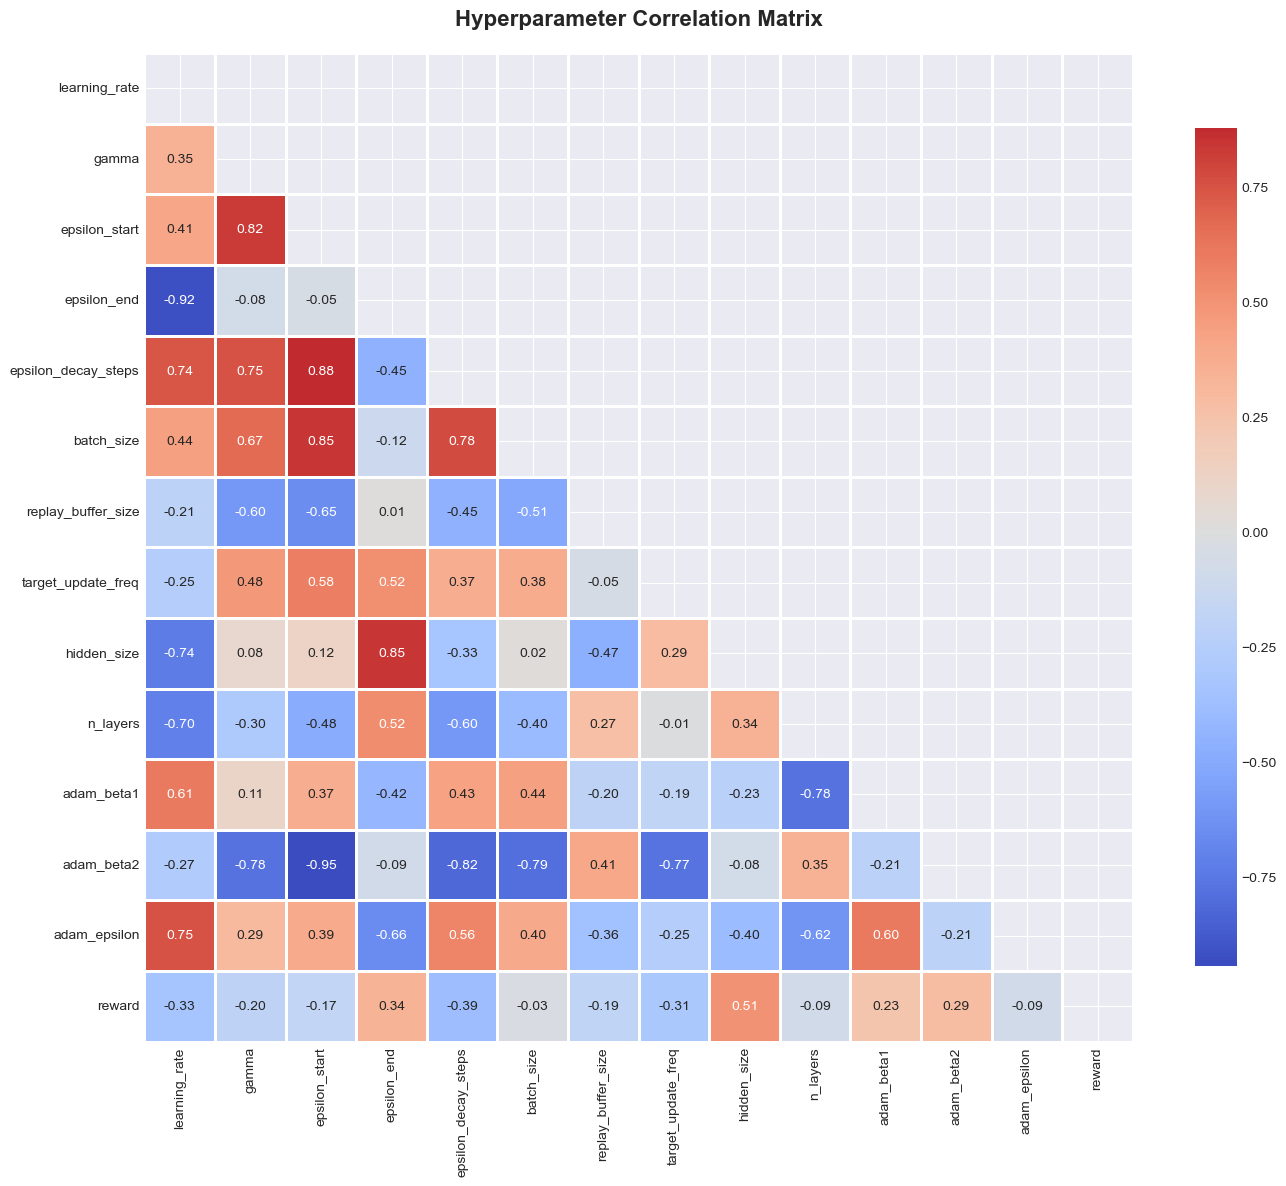


Top Hyperparameters Correlated with Reward:
  hidden_size              :  0.506
  epsilon_decay_steps      : -0.386
  epsilon_end              :  0.337
  learning_rate            : -0.335
  target_update_freq       : -0.307
  adam_beta2               :  0.285
  adam_beta1               :  0.231
  gamma                    : -0.201
  replay_buffer_size       : -0.187
  epsilon_start            : -0.173


In [23]:
# Create correlation matrix between hyperparameters and reward
correlation_data = df.copy()

# Select numeric columns for correlation
numeric_cols = [col for col in correlation_data.columns if correlation_data[col].dtype in ['float64', 'int64']]
corr_matrix = correlation_data[numeric_cols].corr()

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Hyperparameter Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Show top correlations with reward
reward_corr = corr_matrix['reward'].drop('reward').sort_values(ascending=False, key=abs)
print("\nTop Hyperparameters Correlated with Reward:")
print("="*70)
for hp, corr in reward_corr.head(10).items():
    print(f"  {hp:25s}: {corr:6.3f}")
print("="*70)


### 7.6 Summary Statistics


In [24]:
# Display comprehensive summary
print("\n" + "="*70)
print("OPTIMIZATION SUMMARY")
print("="*70)
print(f"\nEnvironment: {CONFIG['env_name']}")
print(f"Total Evaluations: {doa_info['n_evals']}")
print(f"DOA Population Size: {CONFIG['doa_pop_size']}")
print(f"DOA Iterations: {CONFIG['doa_iterations']}")
print(f"DQN Training Steps per Evaluation: {CONFIG['dqn_train_steps']}")

print(f"\n{'Reward Statistics':^70}")
print("-"*70)
print(f"  Best Reward:        {best_reward:>10.2f}")
print(f"  Mean Reward:        {np.mean(rewards):>10.2f}")
print(f"  Std Reward:         {np.std(rewards):>10.2f}")
print(f"  Min Reward:         {np.min(rewards):>10.2f}")
print(f"  Max Reward:         {np.max(rewards):>10.2f}")
print(f"  Improvement:        {best_reward - np.min(rewards):>10.2f}")

print(f"\n{'Best Hyperparameters':^70}")
print("-"*70)
for key, value in sorted(best_hp.items()):
    if isinstance(value, float):
        print(f"  {key:25s}: {value:>15.6f}")
    else:
        print(f"  {key:25s}: {value:>15}")

print("\n" + "="*70)
print("Optimization completed successfully!")
print("="*70)



OPTIMIZATION SUMMARY

Environment: CartPole-v1
Total Evaluations: 15
DOA Population Size: 5
DOA Iterations: 2
DQN Training Steps per Evaluation: 10000

                          Reward Statistics                           
----------------------------------------------------------------------
  Best Reward:            437.40
  Mean Reward:            208.97
  Std Reward:             103.64
  Min Reward:              98.00
  Max Reward:             437.40
  Improvement:            339.40

                         Best Hyperparameters                         
----------------------------------------------------------------------
  adam_beta1               :        0.875079
  adam_beta2               :        0.992573
  adam_epsilon             :        0.000008
  batch_size               :             128
  epsilon_decay_steps      :           26616
  epsilon_end              :        0.077983
  epsilon_start            :        0.591118
  gamma                    :        0.938715
  hi

## 8. Optional: Test Best Configuration

Run a final evaluation with the best hyperparameters found.


In [25]:
# Optional: Final evaluation with best hyperparameters
print("Running final evaluation with best hyperparameters...")
print("="*70)

env = gym.make(CONFIG['env_name'])
agent = DQNAgent(env, best_hp, device=CONFIG['device'], seed=42)

# Train
print(f"Training for {CONFIG['dqn_train_steps']} steps...")
agent.train(CONFIG['dqn_train_steps'], log_interval=CONFIG['dqn_train_steps'] // 5)

# Evaluate
print(f"\nEvaluating on {CONFIG['dqn_eval_episodes'] * 2} episodes...")
final_reward = agent.evaluate(CONFIG['dqn_eval_episodes'] * 2)

print("\n" + "="*70)
print(f"Final Evaluation Reward: {final_reward:.2f}")
print("="*70)

env.close()


Running final evaluation with best hyperparameters...
Training for 10000 steps...
Step 2000/10000 | Avg Reward (last 10): 63.20
Step 4000/10000 | Avg Reward (last 10): 93.50
Step 6000/10000 | Avg Reward (last 10): 192.10
Step 8000/10000 | Avg Reward (last 10): 193.00
Step 10000/10000 | Avg Reward (last 10): 106.00

Evaluating on 10 episodes...

Final Evaluation Reward: 273.10
